### **Distributed Lag Non-Linear Model**

In [27]:
# Import necessary libraries

# Basics
import itertools
import warnings
from IPython.display import display, Markdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# DLNM helpers 
from pydlnm.basis import CrossBasis
from pydlnm.prediction import crosspred
from dlnm import plot_crosspred, cb_pen

# statsmodels for GLMGam
import statsmodels.api as sm
from statsmodels.gam.api import GLMGam
from statsmodels.gam.smooth_basis import UnivariateBSplines, UnivariateCubicCyclicSplines, GenericSmoothers

# PyMC + ArviZ for the final ZINB model
import pymc as pm
import arviz as az

In [28]:
def cb_construct(dataframe, col_lst, max_lag, setting_lst):
    var_degree, var_df, lag_degree, lag_df = setting_lst

    cb_list = []
    for col in col_lst:
        cb = CrossBasis(
            dataframe[col].values, lag=max_lag,
            argvar={"fun": "bs", "degree": var_degree, "df": var_df},
            arglag={"fun": "bs", "degree": lag_degree, "df": lag_df}
        )
        cb_list.append(cb)

    X_exposure = np.concatenate([np.asarray(cb) for cb in cb_list], axis=1)
    n_basis_per_exp = X_exposure.shape[1] // len(col_lst)
    exp_name_list = [f"{col}_basis_{i}" for col in col_lst for i in range(n_basis_per_exp)]

    base = dataframe.reset_index(drop=True).iloc[max_lag:].copy()
    basis_df = pd.DataFrame(X_exposure[max_lag:], columns=exp_name_list, index=base.index)
    model_data = pd.concat([base, basis_df], axis=1)
    
    return model_data, exp_name_list, cb_list

In [29]:
def smoother_construct(dataframe, bs_dict, ccs_dict):
    bs_list = []
    for i, name in enumerate(bs_dict["name"]):
        bs = UnivariateBSplines(dataframe[name].values, df=bs_dict["df"][i], degree=bs_dict["degree"][i], variable_name=name, include_intercept=False)
        bs_list.append(bs)

    ccs_list = []
    for i, name in enumerate(ccs_dict["name"]):
        ccs = UnivariateCubicCyclicSplines(dataframe[name].values, df=ccs_dict["df"][i], variable_name=name, constraints="center")
        ccs_list.append(ccs)

    sm_weights = bs_list + ccs_list
    smooth_names = list(bs_dict["name"]) + list(ccs_dict["name"])
    X_smooth = dataframe[smooth_names]
    
    return GenericSmoothers(X_smooth, sm_weights)

In [30]:
def model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para):
    terms = list(exp_names) + list(linear_predictors)
    formula = f"{tar_var} ~ {' + '.join(terms)}"
    alpha = np.asarray(alpha, dtype=float)

    model = GLMGam.from_formula(formula, data=dataframe, smoother=smoothers, alpha=alpha, family=sm.families.NegativeBinomial(alpha=disp_para))
    result = model.fit()
    
    return model, result

In [31]:
def cb_tune(dataframe, tar_var, exp_col, linear_predictors, bs_dict, ccs_dict, alpha, disp_para, max_lag, grid):
    print(f"{'='*10} Tuning CrossBasis settings {'='*10}")
    best_idx = 0
    performance = []

    for option in grid:
        model_data, exp_names, _ = cb_construct(dataframe, exp_col, max_lag, option)
        smoothers = smoother_construct(model_data, bs_dict, ccs_dict)
        try:
            _, result = model_construct(model_data, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para)
            bic = result.bic
        except Exception as e:
            print(f"option {option} failed: {e}")
            bic = np.inf
        performance.append(bic)
        print(f"BIC for {option}: {bic:.2f}" if np.isfinite(bic) else f"BIC for {option}: failed")

    for i in range(1, len(performance)):
        if performance[i] < performance[best_idx]:
            best_idx = i

    best_setting = grid[best_idx]
    print(f"Best CrossBasis setting: {best_setting} (BIC = {performance[best_idx]:.2f})")
    
    return cb_construct(dataframe, exp_col, max_lag, best_setting)

In [32]:
def smoother_tune(dataframe, tar_var, exp_names, linear_predictors, alpha, disp_para, bs_name_lst, ccs_name_lst, grid):
    print(f"\n{'='*10} Tuning smoother degrees of freedom {'='*10}")
    n_bs = len(bs_name_lst)
    best_idx = 0
    performance = []

    for option in grid:
        bs_dfs = list(option[:n_bs])
        ccs_dfs = list(option[n_bs:])

        bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": bs_dfs}
        ccs_dict = {"name": ccs_name_lst, "df": ccs_dfs}

        smoothers = smoother_construct(dataframe, bs_dict, ccs_dict)
        try:
            _, result = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_para)
            bic = result.bic
            edf = float(np.sum(result.edf))
        except Exception as e:
            print(f"option {option} failed: {e}")
            bic, edf = np.inf, np.nan

        performance.append((bic, edf))
        print(f"Degrees of freedom {option}: BIC={bic:.4f} | sum(EDF)={edf:.4f}")

    for i in range(1, len(performance)):
        if performance[i][0] < performance[best_idx][0]:
            best_idx = i

    best_option = grid[best_idx]
    print(f"Best smoother setting: {best_option} (BIC={performance[best_idx][0]:.4f})")

    bs_dict = {"name": bs_name_lst, "degree": [3] * n_bs, "df": list(best_option[:n_bs])}
    ccs_dict = {"name": ccs_name_lst, "df": list(best_option[n_bs:])}
    
    return smoother_construct(dataframe, bs_dict, ccs_dict)

In [ ]:
def alpha_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, start_alpha, disp_para, criterion_lst=["bic", "gcv"], method="nm"):
    print(f"\n{'='*10} Tuning smoother weights (α) {'='*10}")
    start_alpha = np.asarray(start_alpha, dtype=float)
    model, _ = model_construct(dataframe, tar_var, exp_names, linear_predictors, smoothers, start_alpha, disp_para)

    alpha_out_lst = []
    for criterion in criterion_lst:
        best_alpha = model.select_penweight(criterion=criterion, method=method,
                                            start_params=start_alpha)
        if isinstance(best_alpha, (list, tuple)):
            candidate = best_alpha[0]
            alpha_out = np.asarray(candidate if np.ndim(candidate) > 0 else best_alpha, dtype=float)
        else:
            alpha_out = np.asarray(best_alpha, dtype=float).ravel()
        alpha_out_lst.append(alpha_out)
        print(f"Best alpha found with {criterion}: {alpha_out}")

    # ensure derivative bases exist (original safeguard)
    for s in smoothers.smoothers:
        if getattr(s, "der_basis", None) is None:
            s.der_basis = np.zeros_like(s.basis)
        if getattr(s, "der2_basis", None) is None:
            s.der2_basis = np.zeros_like(s.basis)

    try:
        best_a_kfold = model.select_penweight_kfold()
        alpha_out_lst.append(best_a_kfold[0])
        print(f"Best alpha found with Kfold: {best_a_kfold[0]}")
    except Exception as e:
        print(f"Kfold alpha selection failed: {e}")
        alpha_out_lst.append(alpha_out_lst[0])

    # comparison table
    results = {}
    for name, a in zip(criterion_lst+["KFold"], alpha_out_lst):
        try:
            _, res = model_construct(dataframe, tar_var, exp_names, linear_predictors,
                                    smoothers, a, disp_para)
            results[name] = {"alpha": a, "AIC": res.aic, "BIC": res.bic, "GCV": getattr(res, "gcv", np.nan), "EDF": res.edf.sum()}
        except Exception:
            results[name] = {"alpha": a, "AIC": np.nan, "BIC": np.nan, "GCV": np.nan, "EDF": np.nan}

    print("Alpha values comparison:")
    display(pd.DataFrame(results).T)
    return alpha_out_lst[0]   # return BIC-selected alpha

In [34]:
def disp_tune(dataframe, tar_var, exp_names, linear_predictors, smoothers, alpha, disp_grid):
    print(f"\n{'='*10} Tuning Negative Binomial dispersion parameter {'='*10}")
    performance = []

    for disp in disp_grid:
        try:
            _, result = model_construct(
                dataframe, tar_var, exp_names, linear_predictors,
                smoothers, alpha, disp,
            )
            pearson_ratio = result.pearson_chi2 / result.df_resid
            performance.append((disp, pearson_ratio, result.bic))
            print(f"Dispersion {disp:5.1f}: Pearson ratio = {pearson_ratio:.4f} | BIC = {result.bic:.4f}")
        except Exception as e:
            print(f"Dispersion {disp} failed: {e}")

    if not performance:
        raise RuntimeError("All dispersion values failed.")

    best = min(performance, key=lambda x: abs(x[1] - 1.0))
    print(f"\nBest dispersion parameter: {best[0]} (Pearson ratio = {best[1]:.4f})")
    return best[0]

In [35]:
def extract_smoother_bases(smoothers):

    bases = []
    for s in smoothers.smoothers:
        name = getattr(s, "variable_name", "smooth")
        # statsmodels Univariate* objects store the evaluated basis in .basis
        B = np.asarray(s.basis)
        bases.append((name, B))
    return bases


def build_full_design_matrix(model_data, exp_name_list, linear_predictors_list, smoothers):

    parts = []
    col_names = []

    # 1. Cross-basis columns (already present in model_data)
    X_cb = model_data[exp_name_list].values
    parts.append(X_cb)
    col_names.extend(exp_name_list)

    # 2. Linear predictors
    X_lin = model_data[linear_predictors_list].values
    parts.append(X_lin)
    col_names.extend(linear_predictors_list)

    # 3. Smoother bases
    for name, B in extract_smoother_bases(smoothers):
        parts.append(B)
        col_names.extend([f"{name}_s{i}" for i in range(B.shape[1])])

    X = np.column_stack(parts)
    # drop any constant / all-zero columns that can appear after lag truncation
    keep = np.std(X, axis=0) > 1e-12
    X = X[:, keep]
    col_names = [c for c, k in zip(col_names, keep) if k]

    return X, col_names

In [36]:
def model_construct_zinb(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, prior_sigma=2.0, psi_prior="constant", draws=1000, tune=1000, target_accept=0.95, cores=2, chains=4, random_seed=42):

    y = model_data[tar_var].values.astype("float64")
    X, colnames = build_full_design_matrix(model_data, exp_name_list, linear_predictors_list, smoothers)
    n_obs, n_coef = X.shape
    print(f"Design matrix shape for ZINB: {X.shape}")

    coords = {"coef": colnames, "obs": np.arange(n_obs)}

    with pm.Model(coords=coords) as model:
        # data containers (optional but useful for posterior predictive later)
        X_data = pm.Data("X", X, dims=("obs", "coef"))
        y_data = pm.Data("y", y, dims="obs")

        # coefficients for the count mean (log link)
        beta = pm.Normal("beta", mu=0.0, sigma=prior_sigma, dims="coef")

        eta = pm.math.dot(X_data, beta)
        mu = pm.math.exp(eta)

        # zero-inflation probability
        if psi_prior == "constant":
            psi = pm.Beta("psi", alpha=2.0, beta=2.0)
        else:  # logistic
            gamma = pm.Normal("gamma", mu=0.0, sigma=1.0, dims="coef")
            logit_psi = pm.math.dot(X_data, gamma)
            psi = pm.Deterministic("psi", pm.math.invlogit(logit_psi), dims="obs")

        # dispersion (shape) of the NB component
        alpha = pm.HalfNormal("alpha", sigma=5.0)

        # likelihood
        pm.ZeroInflatedNegativeBinomial("y_obs", psi=psi, mu=mu, alpha=alpha, observed=y_data, dims="obs")

        print("Sampling ZINB model …")
        idata = pm.sample(draws=draws, tune=tune, chains=chains, target_accept=target_accept, cores=cores, random_seed=random_seed, return_inferencedata=True, progressbar=True)

    return model, idata, X, colnames

In [37]:
def extract_cb_coef_from_idata(idata, colnames, exp_name, return_vcov=True):

    basis_names = [n for n in colnames if n.startswith(f"{exp_name}_basis_")]
    if not basis_names:
        raise ValueError(f"No basis coefficients found for exposure '{exp_name}'.")

    # posterior samples of beta: (chain, draw, coef)
    beta_samples = idata.posterior["beta"].sel(coef=basis_names).values
    # flatten chains
    beta_flat = beta_samples.reshape(-1, len(basis_names))

    coef_mean = beta_flat.mean(axis=0)
    if return_vcov:
        vcov = np.cov(beta_flat, rowvar=False)
        return coef_mean, vcov, basis_names
    return coef_mean, None, basis_names

In [38]:
def pred_cal(result_or_idata, cb_list, dataframe, exp_col_list, exp_idx=0, colnames=None):

    exp = exp_col_list[exp_idx]

    if hasattr(result_or_idata, "params"):  # statsmodels path 
        param_names = list(result_or_idata.params.index)
        basis_names = [n for n in param_names if n.startswith(f"{exp}_basis_")]
        if not basis_names:
            raise ValueError(f"No basis coefficients found for exposure '{exp}'.")
        cb_coef = result_or_idata.params[basis_names].values
        cb_vcov = result_or_idata.cov_params().loc[basis_names, basis_names].values
    else:  # PyMC InferenceData path
        if colnames is None:
            raise ValueError("colnames must be provided when using a PyMC idata.")
        cb_coef, cb_vcov, _ = extract_cb_coef_from_idata(
            result_or_idata, colnames, exp, return_vcov=True
        )

    at = np.linspace(dataframe[exp].min(), dataframe[exp].max(), 100)
    cen = float(dataframe[exp].median())

    pred = crosspred(basis=cb_list[exp_idx], coef=cb_coef, vcov=cb_vcov, model_link="log", at=at, cen=cen)
    print(f"{exp} RR range: {pred.allRRfit.min():.3f} to {pred.allRRfit.max():.3f}")
    return pred, exp, cen

In [39]:
def graph_3Dplot(pred, exp_name):
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping 3-D plot.")
        return
    fig = plot_crosspred(pred, ptype="3d")
    ax = fig.gca()
    ax.set_title("3D Exposure-Lag-Response Association Surface", fontsize=14, fontweight="bold", pad=15)
    ax.set_xlabel(exp_name, fontsize=12, labelpad=10)
    ax.set_ylabel("Lag (Weeks)", fontsize=12, labelpad=10)
    ax.set_zlabel("Relative Risk (RR)", labelpad=10)
    try:
        collections = ax.collections[0]
        vmin, vmax = collections.get_array().min(), collections.get_array().max()
        collections.set_clim(vmin, vmax)
        cbar = fig.colorbar(collections, ax=ax, shrink=0.6, pad=0.1)
        cbar.set_label("Relative Risk (RR)", rotation=270, labelpad=20)
    except Exception:
        pass
    plt.tight_layout()
    plt.show()

def graph_exp_plot(pred, exp_name, cen):
    if plot_crosspred is None:
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.plot(pred.at, pred.allRRfit, color="C0", lw=2)
        if hasattr(pred, "allRRlow") and hasattr(pred, "allRRhigh"):
            ax.fill_between(pred.at, pred.allRRlow, pred.allRRhigh, alpha=0.25, color="C0")
        ax.axhline(1, color="gray", ls="--", alpha=0.7)
        ax.axvline(cen, color="black", ls=":", lw=1.2, label=f"Centering {exp_name} ({cen:.4f})")
        ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=12)
        ax.set_xlabel(exp_name, fontsize=12)
        ax.set_ylabel("Relative Risk (RR)", fontsize=12)
        ax.legend(loc="best")
        plt.tight_layout()
        plt.show()
        return

    fig = plot_crosspred(pred, ptype="overall")
    ax = fig.gca()
    ax.axvline(x=cen, color="black", linestyle=":", linewidth=1.2,
               label=f"Centering {exp_name} ({cen:.4f})")
    ax.set_title("Overall Cumulative Exposure-Response Association", fontsize=14, pad=15)
    ax.set_xlabel(exp_name, fontsize=12)
    ax.legend(loc="best", frameon=True)
    plt.show()


def graph_lag_plot(pred, tar_val, exp_name):
    if plot_crosspred is None:
        print("plot_crosspred not available; skipping lag-slice plot.")
        return
    fig = plot_crosspred(pred, ptype="slices", var=tar_val)
    ax = fig.gca()
    ax.set_title(f"Lag-Response Curve at {exp_name} = {tar_val:.4f}",
                 fontsize=14, fontweight="bold")
    ax.set_xlabel("Lag (Weeks)", fontsize=12)
    ax.set_ylabel("Relative Risk (RR)", fontsize=12)
    ax.axhline(1, color="gray", linestyle="--", alpha=0.7)
    plt.show()


def graph_plot(pred, exp_name, cen, lag_slice_val=None):
    graph_3Dplot(pred, exp_name)
    graph_exp_plot(pred, exp_name, cen)
    if lag_slice_val is None:
        lag_slice_val = cen
    graph_lag_plot(pred, lag_slice_val, exp_name)

In [40]:
def model_metric(result):
    print(f"AIC: {result.aic}")
    print(f"BIC: {result.bic}")
    print(f"Deviance: {result.deviance}")
    print(f"Pearson Chi2: {result.pearson_chi2}")
    print(f"Scale/Dispersion: {result.scale}")
    print(f"Effective degree of freedom: \n{result.edf}")
    print(f"Total EDF: {result.edf.sum()}")

In [ ]:
def model_metric_zinb(idata):
    print("===== PyMC ZINB posterior summary (selected parameters) =====")
    display(az.summary(idata, var_names=["psi", "alpha"], round_to=3))
    
    # 
    try:
        print(f"\nWAIC: {az.waic(idata, pointwise=False)}")
        print(f"LOO: {az.loo(idata, pointwise=False)}")
    except Exception:
        try:
            from arviz import waic, loo
            print(waic(idata, pointwise=False))
            print(loo(idata, pointwise=False))
        except Exception as e:
            print(f"WAIC/LOO skipped: {e}")

In [42]:
def residual_diagnostics(result):
    residuals = result.resid_deviance

    # 1. Residuals vs. Fitted Values Plot (checks for systematic bias)
    plt.figure(figsize=(8, 4))
    plt.scatter(result.fittedvalues, residuals, alpha=0.3)
    plt.axhline(0, color='red', linestyle='--')
    plt.xlabel("Fitted Values")
    plt.ylabel("Deviance Residuals")
    plt.title("Residuals vs Fitted")
    plt.show()

    # 2. Autocorrelation Check (ACF) 
    # Time-series data often has uncaptured temporal patterns; residuals should look like white noise.
    fig, ax = plt.subplots(figsize=(8, 4))
    sm.graphics.tsa.plot_acf(residuals, lags=10, ax=ax)
    plt.title("Autocorrelation of Residuals (ACF)")
    plt.show()

In [43]:
def residual_diagnostics_zinb(idata, model_data, tar_var, X, colnames,max_acf_lags=10):
    y = model_data[tar_var].values.astype(float)

    # posterior means
    beta_mean = idata.posterior["beta"].mean(dim=("chain", "draw")).values
    # align with colnames order used when sampling
    if "coef" in idata.posterior["beta"].coords:
        beta_mean = idata.posterior["beta"].mean(dim=("chain", "draw")).sel(coef=colnames).values

    eta = X @ beta_mean
    mu = np.exp(eta)

    # psi (scalar or vector)
    if "psi" in idata.posterior:
        psi_da = idata.posterior["psi"]
        if "obs" in psi_da.dims:
            psi = psi_da.mean(dim=("chain", "draw")).values
        else:
            psi = float(psi_da.mean())
    else:
        psi = 1.0

    alpha = float(idata.posterior["alpha"].mean())

    # Mean and variance of ZINB
    # E[Y] = psi * mu
    # Var[Y] = psi * mu * (1 + mu/alpha) + psi*(1-psi)*mu**2
    mean_hat = psi * mu
    var_hat = psi * mu * (1.0 + mu / alpha) + psi * (1.0 - psi) * mu**2
    var_hat = np.maximum(var_hat, 1e-8)  # numerical safety

    # Pearson residuals
    resid = (y - mean_hat) / np.sqrt(var_hat)

    # ---------- Plots ----------
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    # 1. Residuals vs Fitted
    axes[0].scatter(mean_hat, resid, alpha=0.35, s=12, edgecolors="none")
    axes[0].axhline(0, color="red", ls="--", lw=1)
    axes[0].set_xlabel("Fitted values (E[Y])")
    axes[0].set_ylabel("Pearson residuals")
    axes[0].set_title("Residuals vs Fitted (ZINB)")

    # 2. ACF of residuals
    sm.graphics.tsa.plot_acf(resid, lags=max_acf_lags, ax=axes[1], title="ACF of Pearson residuals")
    axes[1].set_xlabel("Lag")

    # 3. Histogram of residuals
    axes[2].hist(resid, bins=40, density=True, alpha=0.7, edgecolor="white")
    axes[2].axvline(0, color="red", ls="--", lw=1)
    axes[2].set_xlabel("Pearson residual")
    axes[2].set_ylabel("Density")
    axes[2].set_title("Residual distribution")

    plt.tight_layout()
    plt.show()

    # quick numeric summary
    print(f"Pearson residual mean   : {resid.mean():.4f}")
    print(f"Pearson residual std    : {resid.std():.4f}")
    print(f"Proportion of zeros in y: {(y == 0).mean():.3f}")
    print(f"Posterior mean psi      : {np.mean(psi):.3f}")

    return resid, mean_hat


In [ ]:
def DLNM_ZINB(dataframe, max_lag, tar_var, exp_col_list, linear_predictors_list,
              bs_name_lst, ccs_name_lst, cb_grid, smoother_grid, disp_grid, criterion_lst=["bic", "gcv"],
              # PyMC sampling controls
              draws=1500, tune=1500, target_accept=0.9, cores=2, chains=4, 
              psi_prior="logistic", prior_sigma=1.0):

    n_smooth = len(bs_name_lst) + len(ccs_name_lst)
    initial_alpha = np.asarray([20.0] * n_smooth, dtype=float)
    initial_disp = 1.0

    init_bs_dict = {"name": bs_name_lst, "degree": [3] * len(bs_name_lst),
                    "df": [6] * len(bs_name_lst)}
    init_ccs_dict = {"name": ccs_name_lst, "df": [4] * len(ccs_name_lst)}

    # ---------- 1. Original tuning (NB) ----------
    model_data, exp_name_list, cb_list = cb_tune(dataframe, tar_var, exp_col_list, linear_predictors_list, init_bs_dict, init_ccs_dict, initial_alpha, initial_disp, max_lag, cb_grid)

    smoothers = smoother_tune(model_data, tar_var, exp_name_list, linear_predictors_list, initial_alpha, initial_disp, bs_name_lst, ccs_name_lst, smoother_grid)
    best_alpha = alpha_tune(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, initial_alpha, initial_disp, criterion_lst, method="nm")
    best_disp = disp_tune(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, best_alpha, disp_grid)

    # ---------- 2. Original tuning (NB) ----------
    print(f"\n{'='*15} Classic NB GLMGam (for reference) {'='*15}")
    _, nb_result = model_construct(model_data, tar_var, exp_name_list, linear_predictors_list, smoothers, best_alpha, best_disp)
    print(nb_result.summary().tables[1])
    model_metric(nb_result)
    residual_diagnostics(nb_result)

    # ---------- 3. Final PyMC ZINB ----------
    print(f"\n{'='*15} Final PyMC Zero-Inflated Negative Binomial {'='*15}")
    _, idata, X, colnames = model_construct_zinb(
        model_data, tar_var, exp_name_list, linear_predictors_list, smoothers,
        prior_sigma=prior_sigma,
        psi_prior=psi_prior,
        draws=draws, tune=tune, target_accept=target_accept, cores=cores, chains=chains
    )

    model_metric_zinb(idata)

    # ---------- Residual diagnostics ----------
    print("\n--- Residual diagnostics (ZINB) ---")
    resid, _ = residual_diagnostics_zinb(idata, model_data, tar_var, X, colnames, max_acf_lags=10)

    # ---------- 3. Prediction & plots ----------
    pred, exp_name, cen = pred_cal(idata, cb_list, model_data, exp_col_list, exp_idx=0, colnames=colnames)
    graph_plot(pred, exp_name, cen, lag_slice_val=cen)

    return idata, pred, model_data, cb_list, colnames, nb_result, resid


---

In [45]:
# Import data and basic settings
df = pd.read_csv("data.csv")
df.columns = ["Year", "Week", "From", "temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV", "H1", "H3", "B", "AandB", "ContainmentHealthIndex_Average", "pandemic_flag", "Population", "Log_population", "school_flag"]

df.drop(columns=["From"], inplace=True)
df["time"] = np.arange(1, len(df) + 1)

mete_col = ["temprange", "temp", "RH", "SR", "AP", "DPT", "WS", "UV"]
flu_col = ["H1", "H3", "B", "AandB"]
spline_col = ["ContainmentHealthIndex_Average", "Week", "time"]

In [46]:
# Overview 
display(df.head())
df.info()
display(df.describe())

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,Population,Log_population,school_flag,time
0,2002,36,14.3,28.15,76.5,19.66,1008.20,23.20,7.35,4.0,1,12,3.0,19,0.0,0.0,6725.8,8.813706,1.0,1
1,2002,37,13.6,26.70,85.0,9.35,1006.30,23.80,10.50,3.0,0,6,4.0,15,0.0,0.0,6725.8,8.813706,1.0,2
2,2002,38,11.2,26.40,83.0,16.75,1011.35,23.20,13.45,4.0,0,4,4.0,13,0.0,0.0,6725.8,8.813706,1.0,3
3,2002,39,10.0,25.90,85.0,10.93,1012.90,23.25,13.25,3.0,0,2,6.0,10,0.0,0.0,6725.8,8.813706,1.0,4
4,2002,40,10.6,25.95,82.0,11.56,1012.80,22.40,10.05,3.0,0,6,2.0,8,0.0,0.0,6725.8,8.813706,1.0,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1253 entries, 0 to 1252
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Year                            1253 non-null   int64  
 1   Week                            1253 non-null   int64  
 2   temprange                       1253 non-null   float64
 3   temp                            1253 non-null   float64
 4   RH                              1253 non-null   float64
 5   SR                              1253 non-null   float64
 6   AP                              1253 non-null   float64
 7   DPT                             1253 non-null   float64
 8   WS                              1253 non-null   float64
 9   UV                              1253 non-null   float64
 10  H1                              1253 non-null   int64  
 11  H3                              1253 non-null   int64  
 12  B                               12

,Year,Week,temprange,temp,RH,SR,AP,DPT,WS,UV,H1,H3,B,AandB,ContainmentHealthIndex_Average,pandemic_flag,Population,Log_population,school_flag,time
count,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1252.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000,1253.000000
mean,2014.172386,26.605746,14.864006,23.383599,78.736233,13.996983,1012.860774,19.225339,10.074062,2.891700,69.613727,115.727055,44.593450,261.437350,8.128132,0.131684,7208.379808,8.882321,0.904230,627.000000
std,6.945058,15.077257,3.539967,5.005770,8.494599,5.270534,6.067874,5.963239,1.811932,1.256406,189.083854,233.728958,131.615377,439.621172,21.983305,0.338282,264.439683,0.036944,0.294393,361.854252
min,2002.000000,1.000000,3.900000,8.900000,43.000000,2.020000,996.750000,-0.100000,5.550000,0.400000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6725.800000,8.813706,0.000000,1.000000
25%,2008.000000,14.000000,12.200000,19.100000,74.500000,9.930000,1008.000000,14.900000,8.800000,2.000000,0.000000,5.000000,3.000000,27.000000,0.000000,0.000000,6963.900000,8.848495,1.000000,314.000000
50%,2014.000000,27.000000,14.000000,24.400000,80.000000,14.240000,1012.800000,20.500000,10.000000,3.000000,4.000000,28.000000,12.500000,103.000000,0.000000,0.000000,7252.900000,8.889157,1.000000,627.000000
75%,2020.000000,40.000000,17.000000,28.000000,85.000000,17.680000,1017.650000,24.800000,11.200000,4.000000,47.000000,125.000000,41.000000,305.000000,0.000000,0.000000,7472.600000,8.918998,1.000000,940.000000
max,2026.000000,53.000000,27.700000,31.700000,94.000000,26.460000,1027.700000,26.800000,17.800000,7.000000,1999.000000,2560.000000,1978.000000,4679.000000,82.140000,1.000000,7536.100000,8.927460,1.000000,1253.000000


In [47]:
# Ignore warnings in the tuning stage
warnings.filterwarnings("ignore", message=".*Singular matrix.*")
warnings.filterwarnings("ignore", message=".*singular matrix.*")
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="statsmodels")
warnings.filterwarnings("ignore", category=FutureWarning)

In [ ]:
# Basic setting for DLNM construction
linear_predictors_list = ["pandemic_flag", "Log_population", "school_flag"]
bs_name_lst = ["time", "ContainmentHealthIndex_Average"]
ccs_name_lst = ["Week"]

# Grids for tuning
cb_grid = list(itertools.product([2, 3], [3, 4], [2, 3], [3, 4]))
smoother_grid = list(itertools.product([15, 20, 25, 30, 35], [4, 5, 6, 7], [6, 8, 10, 12]))
disp_grid = [1.0, 1.5, 2.0, 3.0, 5.0]

**============================== temprange (ZINB) ==============================**

========== Tuning CrossBasis settings ==========
BIC for (2, 3, 2, 3): 9568.80
BIC for (2, 3, 2, 4): 9591.22
BIC for (2, 3, 3, 3): 9591.22
BIC for (2, 3, 3, 4): 9591.22
BIC for (2, 4, 2, 3): 9573.24
BIC for (2, 4, 2, 4): 9602.38
BIC for (2, 4, 3, 3): 9602.38
BIC for (2, 4, 3, 4): 9602.38
BIC for (3, 3, 2, 3): 9568.71
BIC for (3, 3, 2, 4): 9591.48
BIC for (3, 3, 3, 3): 9591.48
BIC for (3, 3, 3, 4): 9591.48
BIC for (3, 4, 2, 3): 9585.88
BIC for (3, 4, 2, 4): 9616.33
BIC for (3, 4, 3, 3): 9616.33
BIC for (3, 4, 3, 4): 9616.33
Best CrossBasis setting: (3, 3, 2, 3) (BIC = 9568.71)

========== Tuning smoother degrees of freedom ==========
Degrees of freedom (12, 4, 6): BIC=9271.6191 | sum(EDF)=31.2590
Degrees of freedom (12, 4, 8): BIC=9291.0148 | sum(EDF)=32.7106
Degrees of freedom (12, 4, 10): BIC=9288.9170 | sum(EDF)=33.8568
Degrees of freedom (12, 4, 12): BIC=9289.4764 | sum(EDF)=35.1349
Degrees of freedom (12, 5, 6): BIC=9271.6191 | sum(EDF)=31.2590
Degrees of freedom (12, 5, 8): BIC=92

,alpha,AIC,BIC,GCV,EDF
BIC,"[35.62981318137949, 27.757290928007368, 27.238...",7856.661576,8152.790552,1.099259,57.723838
GCV,"(1.0, 25.118864315095795, 25.118864315095795)",7756.429058,7899.037075,1.046044,27.7983



========== Tuning Negative Binomial dispersion parameter ==========
Dispersion   0.5: Pearson ratio = 2.5115 | BIC = 8528.1391
Dispersion   1.0: Pearson ratio = 1.7828 | BIC = 8152.7906
Dispersion   1.5: Pearson ratio = 1.4250 | BIC = 7968.7757
Dispersion   2.0: Pearson ratio = 1.2261 | BIC = 8345.9203
Dispersion   3.0: Pearson ratio = 0.8539 | BIC = 8464.2935
Dispersion   5.0: Pearson ratio = 0.4842 | BIC = 8951.6598

Best dispersion parameter: 3.0 (Pearson ratio = 0.8539)

=============== Classic NB GLMGam (for reference) ===============
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                          -655.7812    1.5e+07  -4.36e-05      1.000   -2.95e+07    2.95e+07
temprange_basis_0                     1.8512      2.453      0.755      0.451      -2.957       6.660
temprange_basis_1                     2.1389 

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, gamma, alpha]


Output()

Sampling 4 chains for 1_500 tune and 1_500 draw iterations (6_000 + 6_000 draws total) took 363 seconds.


===== PyMC ZINB posterior summary (selected parameters) =====


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
psi[0],0.827,0.062,0.719,0.911,8737.279,5531.296,1.001,0.001,0.001
psi[1],0.833,0.062,0.722,0.918,8294.999,5520.587,1.001,0.001,0.001
psi[2],0.828,0.069,0.703,0.921,7873.624,5158.581,1.001,0.001,0.001
psi[3],0.804,0.080,0.663,0.912,7702.609,4971.481,1.001,0.001,0.001
psi[4],0.766,0.089,0.609,0.891,7535.289,5096.052,1.000,0.001,0.001
...,...,...,...,...,...,...,...,...,...
psi[1245],0.933,0.049,0.839,0.984,9856.816,4013.625,1.000,0.001,0.001
psi[1246],0.930,0.054,0.827,0.985,9906.544,4248.740,1.000,0.001,0.001
psi[1247],0.927,0.061,0.809,0.987,10310.535,4116.920,1.000,0.001,0.001
psi[1248],0.919,0.081,0.762,0.991,10774.715,5116.760,1.000,0.001,0.002


WAIC/LOO skipped: cannot import name 'waic' from 'arviz' (c:\Users\yanss\anaconda3\Lib\site-packages\arviz\__init__.py)

--- Residual diagnostics (ZINB) ---


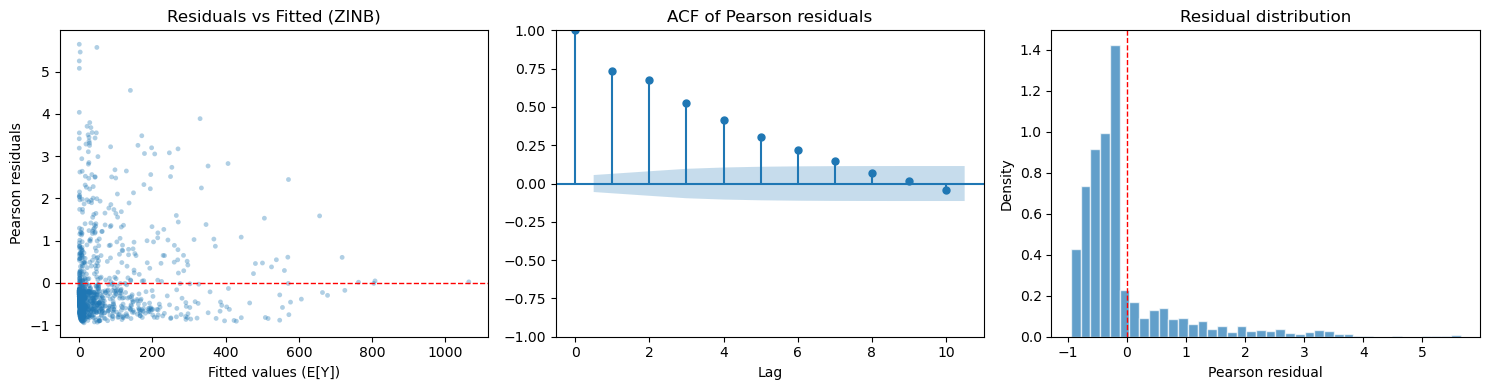

Pearson residual mean   : -0.0412
Pearson residual std    : 0.9384
Proportion of zeros in y: 0.376
Posterior mean psi      : 0.677
temprange RR range: 0.377 to 5.911


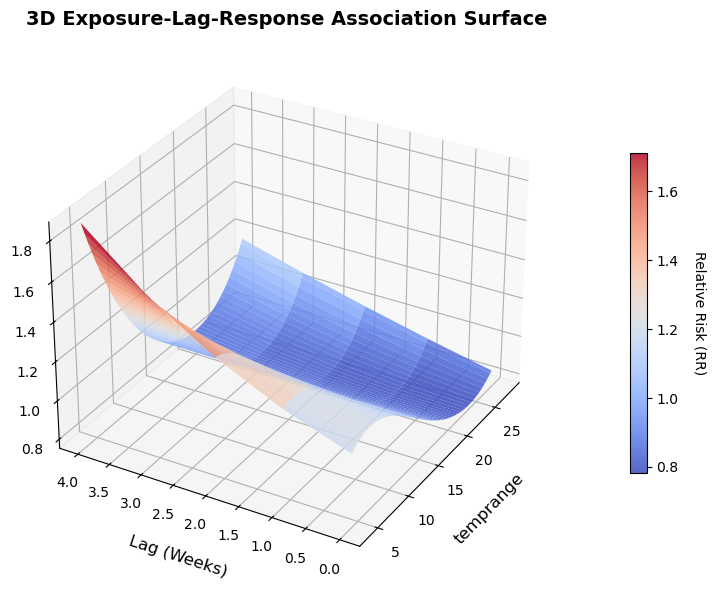

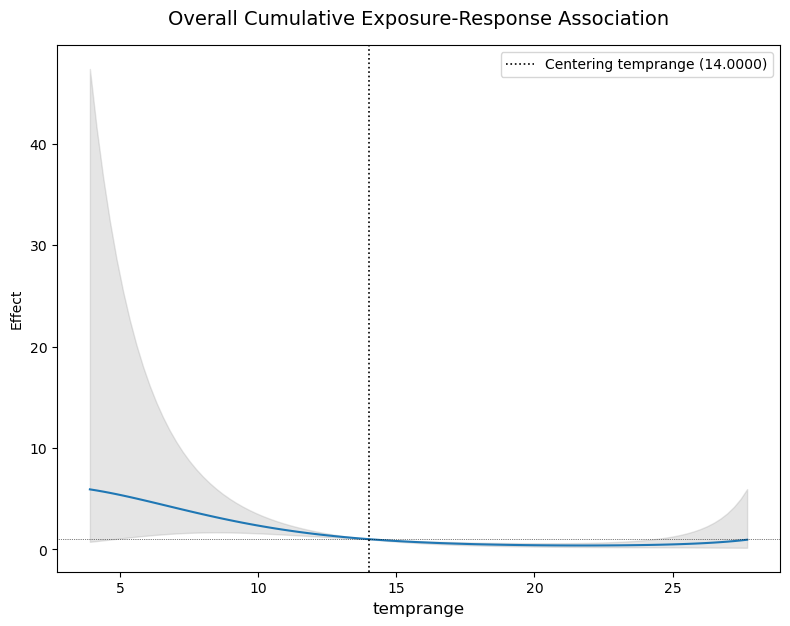

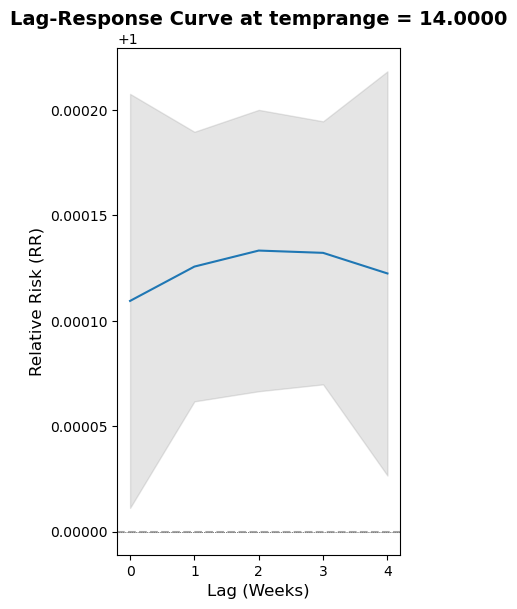

In [49]:
tar_var = "H1"
exp = mete_col[0]
exp_col_list = [exp]

display(Markdown(f"**{'='*30} {exp} (ZINB) {'='*30}**"))

idata, pred, model_data, cb_list, colnames, nb_result, resid = DLNM_ZINB(
    df, max_lag=4,
    tar_var=tar_var, exp_col_list=exp_col_list, linear_predictors_list=linear_predictors_list,
    bs_name_lst=bs_name_lst, ccs_name_lst=ccs_name_lst,
    cb_grid=cb_grid, smoother_grid=smoother_grid, disp_grid=disp_grid, criterion_lst=["bic"],
    # PyMC controls – reduce draws/tune for a quick test
    draws=1500, tune=1500, target_accept=0.95, cores=4, psi_prior="logistic", prior_sigma=1.0
)


In [50]:
print("Pearson residual summary (from DLNM_ZINB):")
print(f"  mean = {resid.mean():.4f}")
print(f"  std  = {resid.std():.4f}")


Pearson residual summary (from DLNM_ZINB):
  mean = -0.0412
  std  = 0.9384


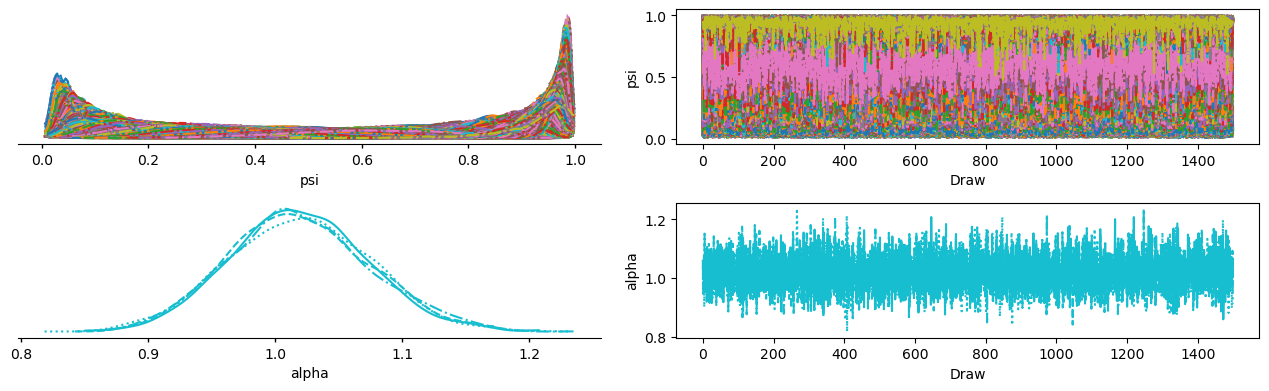

            mean     sd  eti89_lb  eti89_ub   ess_bulk  ess_tail  r_hat  \
psi[0]     0.827  0.062     0.719     0.911   8737.279  5531.296  1.001   
psi[1]     0.833  0.062     0.722     0.918   8294.999  5520.587  1.001   
psi[2]     0.828  0.069     0.703     0.921   7873.624  5158.581  1.001   
psi[3]     0.804  0.080     0.663     0.912   7702.609  4971.481  1.001   
psi[4]     0.766  0.089     0.609     0.891   7535.289  5096.052  1.000   
...          ...    ...       ...       ...        ...       ...    ...   
psi[1245]  0.933  0.049     0.839     0.984   9856.816  4013.625  1.000   
psi[1246]  0.930  0.054     0.827     0.985   9906.544  4248.740  1.000   
psi[1247]  0.927  0.061     0.809     0.987  10310.535  4116.920  1.000   
psi[1248]  0.919  0.081     0.762     0.991  10774.715  5116.760  1.000   
alpha      1.019  0.056     0.932     1.111  12512.546  4799.458  1.000   

           mcse_mean  mcse_sd  
psi[0]         0.001    0.001  
psi[1]         0.001    0.001  
psi

In [ ]:
az.rcParams['plot.max_subplots'] = 1300

az.plot_trace_dist(idata, var_names=["psi", "alpha"])
plt.tight_layout()
plt.show()

display(az.summary(idata, var_names=["psi", "alpha"], round_to=3))